# Advection-diffusion

$$u_t = -c\, u_x + \nu\, u_{xx}, \qquad x \in [0, 2\pi) \text{ periodic}, \qquad c = 1,\ \nu = 0.05 .$$

Linear, with two true terms. 32 periodic nodes, $\Delta t = 0.04$, 26 time columns ($t \le 1$); observed: the initial
column and 150 random nodes of the later columns (22 %). Rollouts to $t = 2$.

The pipeline is the one of `burgers_walkthrough.ipynb` on a periodic grid (`SpaceTimeGrid(..., period=P)`): the PDE
is collocated at every node and the state kernel is the periodic Gaussian `PeriodicKernel`. The reference solver is
`problems/periodic_reference.py`.

**What to expect.** In our run Step 2 keeps the right features but represents $u_{xx}$ by `rbf[u_xx]` instead of
`linear[u_xx]`: with these data the RBF atom reproduces a linear function of $u_{xx}$, the CV cannot tell the two
apart, and backward elimination happens to drop the linear atom first. The rollout is not affected; the coefficient
of $u_{xx}$ is then not read off directly.

In [1]:
# On Colab: clone the repository and install the package (no restart needed). Locally: run from the repository.
import os, sys
from pathlib import Path
if "google.colab" in sys.modules and not Path("/content/Kernel-Timestepping").exists():
    !git clone -q https://github.com/jinni1114/Kernel-Timestepping.git /content/Kernel-Timestepping
    !pip install -q "/content/Kernel-Timestepping[examples]"
# problems/ and experiments/ are not installed with the package: put the repository root and experiments/ on the path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents, Path("/content/Kernel-Timestepping")] if (p / "pyproject.toml").exists())
sys.path[:0] = [str(REPO), str(REPO / "experiments")]

import copy, time
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jaxkernels import PeriodicKernel

import kernel_timestepping as kt
from problems.periodic_reference import PeriodicReferenceSolution, solve_periodic, advection_diffusion
import plot_style as ph
ph.use_style()

/tmp/claude-0/-home-claude/424d59ec-acc9-5023-b22f-ac72564c8941/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

In [2]:
EQUATION = advection_diffusion(c=1.0, nu=0.05)
PERIOD, N_X, DT, N_T, N_OBS, MAX_ORDER, MAX_COND = 2 * np.pi, 32, 0.04, 26, 150, 3, 1e12
T_ROLL, BURN_IN = 2.0, 0.0
u0 = lambda x: np.exp(np.sin(x)) - 1 + 0.3 * np.cos(2 * x)

# Reference solution (spectral ETDRK4 on 256 modes), saved every DT/4; t is shifted so that the data start at t = 0
t_ref, x_ref, u_ref = solve_periodic(EQUATION, u0, PERIOD, n=256, dt=min(1e-3, DT / 20), t_final=BURN_IN + T_ROLL + 2 * DT,
                                     save_every=max(1, round(DT / 4 / min(1e-3, DT / 20))))
truth = PeriodicReferenceSolution(EQUATION, t_ref - BURN_IN, x_ref, u_ref, PERIOD)

grid = kt.SpaceTimeGrid(kt.periodic_nodes(N_X, PERIOD), dt=DT, n_t=N_T, period=PERIOD)
obs = kt.sample_nodal_observations(grid, lambda t, x: truth.u(t, x, grid=False), n_interior=N_OBS, seed=0)
print(f"{len(obs)} observations of {grid.n_t * grid.n_x} nodes ({len(obs) / (grid.n_t * grid.n_x):.0%})")

182 observations of 832 nodes (22%)


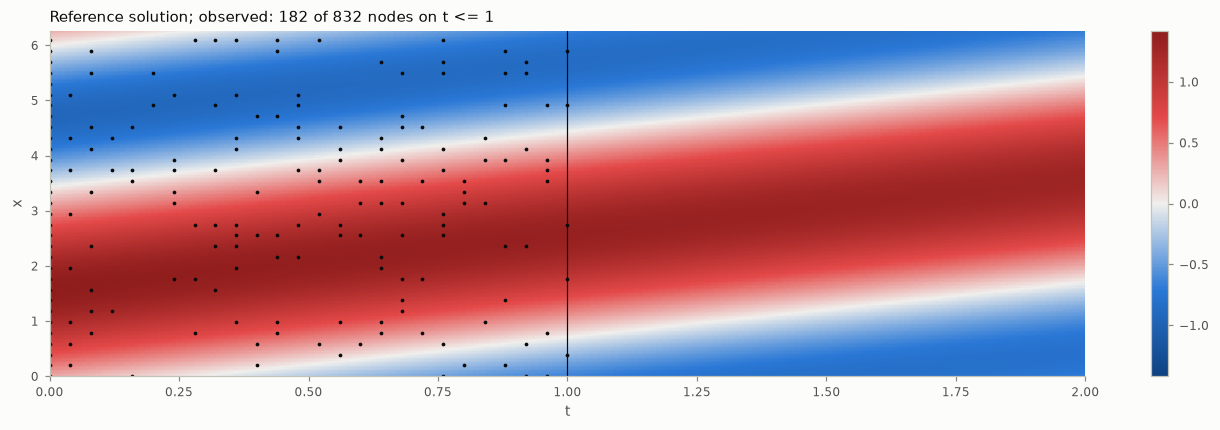

In [3]:
# Reference solution over the whole rollout window, and the observed nodes (black) on the training window
t_fine, x_fine = np.linspace(0, T_ROLL, 301), np.linspace(0, PERIOD, 257)[:-1]
fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
mesh = ph.field_map(ax, t_fine, x_fine, truth.u(t_fine, x_fine), np.abs(truth.values).max(),
                    f"Reference solution; observed: {len(obs)} of {grid.n_t * grid.n_x} nodes on t <= {grid.t[-1]:g}")
ax.scatter(grid.t[obs.n], grid.x[obs.k], s=6, color=ph.INK, linewidths=0)
ax.axvline(grid.t[-1], color=ph.INK, lw=0.8)
ax.set(xlabel="t", ylabel="x"); fig.colorbar(mesh, ax=ax)

## 2. Two-step soft fit and atom selection

In [4]:
# State kernel: periodic Gaussian, lengthscale from the GP fit (x 0.75), reduced if needed so that cond(K) <= 1e12
ell = kt.state_lengthscale(grid, obs, max_cond=MAX_COND)
model = kt.KMDTimeStepper(PeriodicKernel(period=PERIOD, lengthscale=ell), grid, max_order=MAX_ORDER)
start = time.time()
model.fit(obs)                                          # Step 1 (state fit, lam_addot by CV) + Step 2 soft + selection
print(f"lengthscale {ell:.4f}, cond(K) {np.linalg.cond(model.basis.K):.1e}, lam_addot {model.state_cv_.best:g}  ({time.time() - start:.0f} s)")
print(model.summary())
print("true:   ", "  ".join(f"{name} {value:+g}" for name, value in EQUATION.terms.items()))

lengthscale 0.6352, cond(K) 1.0e+12, lam_addot 3.16228e-08  (53 s)
method: two_step_soft
selected atoms: const, linear[u_x], rbf[u_xx]
P_hat(s) = +0.0008881 -1 u_x + [rbf[u_xx]]
true:    u_x -1  u_xx +0.05


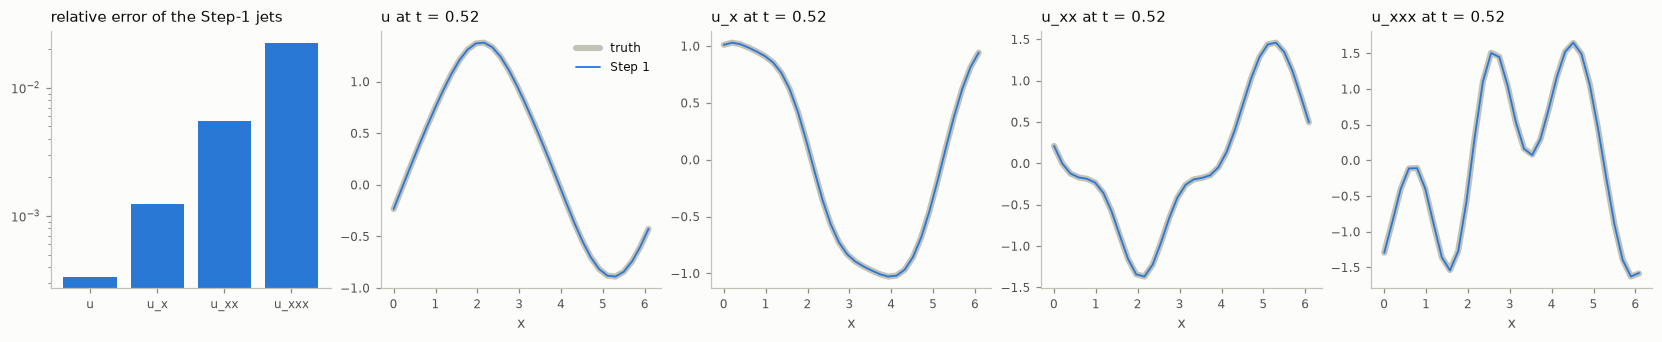

In [5]:
# Step-1 state and its x-derivatives against the truth at the collocation nodes: these errors are what the
# operator regression sees (errors in a feature bias its coefficient towards zero)
jets_fit = np.asarray(model.basis.jets(jnp.asarray(model.alpha_)))
jets_true = truth.jets(grid.t, grid.x, MAX_ORDER)
names = [kt.derivative_name(q) for q in range(MAX_ORDER + 1)]
errors = [kt.relative_l2(jets_fit[..., q], jets_true[..., q]) for q in range(MAX_ORDER + 1)]
n_mid = grid.n_t // 2
fig, axes = plt.subplots(1, MAX_ORDER + 2, figsize=(3.0 * (MAX_ORDER + 2), 3.0), layout="constrained")
axes[0].bar(names, errors, color=ph.BLUE); axes[0].set(yscale="log", title="relative error of the Step-1 jets")
for q, ax in enumerate(axes[1:]):
    ax.plot(grid.x, jets_true[n_mid, :, q], color=ph.NEUTRAL, lw=4, label="truth")
    ax.plot(grid.x, jets_fit[n_mid, :, q], color=ph.BLUE, lw=1.2, label="Step 1")
    ax.set(title=f"{names[q]} at t = {grid.t[n_mid]:g}", xlabel="x")
axes[1].legend()

## 3. Refits and rollouts

In [6]:
# The other methods refit the selected atoms, started from the two-step soft fit. one_step_soft runs the
# 5-fold CV for lam_dyn and lam_addot (about 21 x 5 L-BFGS fits): set RUN_ONE_STEP_SOFT = True to include it.
RUN_ONE_STEP_SOFT = False
fits = {"two_step_soft": model}
for method, refit in [("two_step_hard", lambda m: m.refit_two_step_operator_hard()),
                      ("one_step_soft", lambda m: m.refit_one_step_soft(obs)),
                      ("one_step_hard", lambda m: m.refit_one_step_hard(obs))]:
    if method == "one_step_soft" and not RUN_ONE_STEP_SOFT:
        continue
    start = time.time()
    fits[method] = refit(copy.copy(model))
    print(f"{method}: {time.time() - start:.0f} s, converged: {getattr(fits[method].refit_result_, 'converged', fits[method].refit_result_.success)}")

two_step_hard: 12 s, converged: True


one_step_hard: 33 s, converged: True


In [7]:
# Rollouts from the true initial column out to T_ROLL (training window: t <= grid.t[-1]), and the same rollout of the
# TRUE equation in the same kernel stepper: the floor set by the discretisation (kernel basis + theta scheme)
n_roll = int(round(T_ROLL / grid.dt))
t_roll = grid.dt * np.arange(n_roll + 1)
exact = truth.u(t_roll, grid.x)
features = kt.default_features(MAX_ORDER)
true_operator = lambda jets, _: sum(c * features[[f.name for f in features].index(n)].fn(jets) for n, c in EQUATION.terms.items())
floor_stepper = kt.ThetaStepper(model.basis, true_operator, grid.dt, model.theta, model.newton_iters)
rollouts = {"true equation": np.asarray(model.basis.values(floor_stepper.rollout(model.basis.interpolate(exact[0]), jnp.zeros(1), n_roll)))}
rollouts.update({method: m.rollout(exact[0], n_steps=n_roll) for method, m in fits.items()})

print(f"{'method':16s} {'rollout error':>14s}   coefficients of the linear atoms (true: {EQUATION.terms})")
for method, values in rollouts.items():
    line = f"{method:16s} {kt.relative_l2(values, exact):14.2e}"
    if method in fits:
        slopes, constant = fits[method].library_.linear_coefficients(fits[method].coef_)
        kernel_atoms = [a.name for a in fits[method].library_.atoms if a.size > 1]
        line += "   " + "  ".join(f"{k} {v:+.5f}" for k, v in slopes.items()) + (f"   + {kernel_atoms}" if kernel_atoms else "")
    print(line)

method            rollout error   coefficients of the linear atoms (true: {'u_x': -1.0, 'u_xx': 0.05})
true equation          1.70e-04
two_step_soft          9.07e-04   u_x -1.00022   + ['rbf[u_xx]']
two_step_hard          1.03e-04   u_x -1.00012   + ['rbf[u_xx]']
one_step_hard          7.77e-05   u_x -1.00014   + ['rbf[u_xx]']


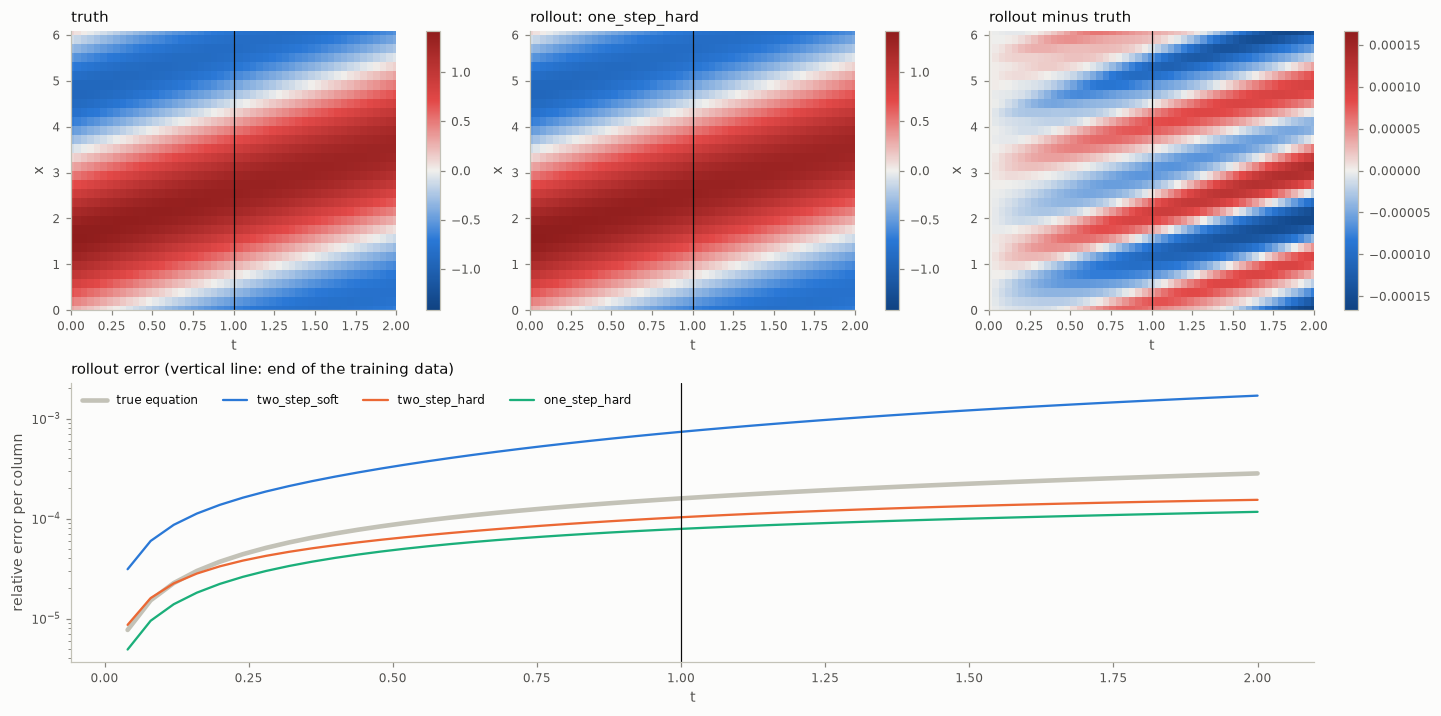

In [8]:
# Visual check: truth, rollout of the best fit, their difference; error per time column for every method
best = min(fits, key=lambda m: kt.relative_l2(rollouts[m], exact))
fig = plt.figure(figsize=(13, 6.4), layout="constrained")
panels = fig.add_gridspec(2, 3)
limit = np.abs(exact).max()
for i, (values, title) in enumerate([(exact, "truth"), (rollouts[best], f"rollout: {best}"),
                                     (rollouts[best] - exact, "rollout minus truth")]):
    ax = fig.add_subplot(panels[0, i])
    mesh = ph.field_map(ax, t_roll, grid.x, values, limit if i < 2 else np.abs(values).max(), title)
    ax.axvline(grid.t[-1], color=ph.INK, lw=0.8); ax.set(xlabel="t", ylabel="x"); fig.colorbar(mesh, ax=ax)
ax = fig.add_subplot(panels[1, :])
for (method, values), color in zip(rollouts.items(), [ph.NEUTRAL, ph.BLUE, ph.ORANGE, ph.AQUA, ph.INK]):
    err = np.linalg.norm(values - exact, axis=1)[1:] / np.linalg.norm(exact, axis=1)[1:]
    ax.plot(t_roll[1:], err, color=color, lw=3 if method == "true equation" else 1.5, label=method)
ax.axvline(grid.t[-1], color=ph.INK, lw=0.8)
ax.set(yscale="log", xlabel="t", ylabel="relative error per column", title="rollout error (vertical line: end of the training data)")
ax.legend(ncol=5)